# 🐼📈 Pandas і графіки для аналітиків · Блокнот 1 з 7
## Знайомство з pandas · 📈 Перший графік

**pandas** — це бібліотека Python для роботи з таблицями. Уявіть собі Excel, у якому можна:
- відкрити файл на мільйон рядків, і нічого не зависне;
- один раз написати фільтри, формули й зведені таблиці, а потім повторювати їх для нового файлу одним кліком;
- об'єднати дані з кількох джерел без ВПР (VLOOKUP).

Саме тому pandas — основний інструмент аналітика даних у Python.

### У цьому блокноті ви навчитеся
1. Що таке **Series** і **DataFrame**: два головні «будівельні блоки» pandas.
2. Як **завантажити таблицю** з файлу.
3. Як зробити **перший огляд даних**: скільки рядків, які стовпці, чи є пропуски.
4. Як порахувати перші **підсумки**: суму, середнє, мінімум, максимум.
5. 📈 Як побудувати **перший графік** однією командою і зробити його зрозумілим: заголовок, підписи осей.
6. 📈 Який графік обрати: лінійний, стовпчиковий чи гістограму.

### Як працювати з блокнотом
- Запускайте клітинки **по черзі зверху вниз**: кнопка ▶ ліворуч або **`Shift + Enter`**.
- **Першою** запустіть клітинку «📦 Підготовка даних»: вона створить файли з даними.
- Змінюйте числа й умови в прикладах і дивіться, що вийде. Зламати нічого не можна.
- У практиці пишіть код у клітинках «Ваш код тут». Розв'язки всіх завдань зібрані в **останній клітинці** блокнота. Спершу спробуйте самостійно, а туди зазирайте, лише якщо справді застрягли.
- Розділи з позначкою **📈** — про графіки. Вони йдуть паралельно з pandas і поступово ускладнюються від блокнота до блокнота.

<details>
<summary><b>📚 Увесь курс</b></summary>

**01. Знайомство з pandas · 📈 Перший графік** ← ви тут<br>02. Вибір, фільтрація та сортування · 📈 Налаштовуємо вигляд графіка<br>03. Нові стовпці та очищення даних · 📈 Графіки для перевірки даних<br>04. Групування та зведені таблиці · 📈 Графіки з групувань<br>05. Об'єднання таблиць · 📈 Порівняння і зв'язки<br>06. Робота з датами · 📈 Графіки динаміки<br>07. Фінальний проєкт · 📈 Дашборд для керівника

</details>

## Крок 0. Дані для навчання

У роботі аналітик отримує файли: вивантаження з CRM, облікової системи, Google Таблиць. У цьому курсі ми працюємо з даними **вигаданого інтернет-магазину** за 2025 рік: замовлення, клієнти, товари.

Клітинка нижче створює ці файли. **Запустіть її** (вона схована, щоб не відволікати; код можна відкрити, але розбиратися в ньому не потрібно).

In [2]:
# @title 📦 Підготовка даних — просто запустіть цю клітинку (Shift + Enter)
# Ця клітинка створює навчальні файли з даними інтернет-магазину за 2025 рік.
# Розбиратися в її коді не потрібно.
# Якщо Colab перезапустився і файли зникли — просто запустіть її ще раз.

# Імпортуємо бібліотеку NumPy для математичних розрахунків та генерації чисел
import numpy as np
# Імпортуємо бібліотеку Pandas для роботи з таблицями (DataFrame)
import pandas as pd
# Імпортуємо модуль pyplot з Matplotlib для можливої побудови графіків
import matplotlib.pyplot as plt

# Ініціалізуємо сучасний генератор випадкових чисел NumPy із фіксованим seed 2025 для відтворюваності
rng = np.random.default_rng(2025)

# ---------- Товари ----------
# Створюємо базову таблицю товарів, вручну прописуючи список кортежів із даними
products = pd.DataFrame(
    [
        ("P01", "Headphones", "Electronics", 1500, 900),
        ("P02", "Power bank", "Electronics", 900, 520),
        ("P03", "Smartwatch", "Electronics", 4200, 2900),
        ("P04", "Bluetooth speaker", "Electronics", 2100, 1300),
        ("P05", "T-shirt", "Clothing", 450, 180),
        ("P06", "Hoodie", "Clothing", 1200, 550),
        ("P07", "Jeans", "Clothing", 1600, 800),
        ("P08", "Sneakers", "Clothing", 2800, 1600),
        ("P09", "Mug", "Home", 180, 60),
        ("P10", "Blanket", "Home", 850, 400),
        ("P11", "Desk lamp", "Home", 1100, 600),
        ("P12", "Towel set", "Home", 650, 300),
        ("P13", "Face cream", "Beauty", 520, 210),
        ("P14", "Shampoo", "Beauty", 260, 110),
        ("P15", "Perfume", "Beauty", 2400, 1300),
        ("P16", "Yoga mat", "Sports", 700, 320),
        ("P17", "Water bottle", "Sports", 350, 140),
        ("P18", "Dumbbells 5 kg", "Sports", 950, 550),
    ],
    columns=["product_id", "product", "category", "price", "cost"],
)  # Задаємо назви колонок: ID, назва, категорія, ціна продажу, собівартість

# ---------- Клієнти ----------
# Визначаємо загальну кількість унікальних клієнтів (400 осіб)
n_cust = 400
# Створюємо пул базових імен для випадкового вибору
names = [
    "Olena",
    "Andrii",
    "Mariia",
    "Ihor",
    "Nataliia",
    "Dmytro",
    "Iryna",
    "Oleksandr",
    "Tetiana",
    "Serhii",
    "Yuliia",
    "Maksym",
    "Oksana",
    "Viktor",
    "Anna",
    "Bohdan",
    "Kateryna",
    "Taras",
    "Sofiia",
    "Roman",
]
# Створюємо список міст проживання клієнтів
cities = ["Kyiv", "Lviv", "Odesa", "Kharkiv", "Dnipro"]
# Генеруємо масив випадкових зміщень у днях (від 0 до 3 років) та додаємо до стартової дати 2022-01-01
reg = pd.Timestamp("2022-01-01") + pd.to_timedelta(
    rng.integers(0, 3 * 365, n_cust), unit="D"
)
# Збираємо фінальну таблицю клієнтів
customers = pd.DataFrame(
    {
        # Генеруємо текстові ID від C0001 до C0400 за допомогою форматування f-рядків
        "customer_id": [f"C{i:04d}" for i in range(1, n_cust + 1)],
        # Вибираємо випадкові імена для 400 клієнтів (із повтореннями)
        "name": rng.choice(names, n_cust),
        # Вибираємо міста згідно із заданими ймовірностями (найбільше з Києва — 35%)
        "city": rng.choice(cities, n_cust, p=[0.35, 0.2, 0.15, 0.15, 0.15]),
        # Генеруємо вік за нормальним розподілом (середній 33, розкид 9), обрізаємо від 18 до 65 років і приводимо до int
        "age": np.clip(rng.normal(33, 9, n_cust).round(), 18, 65).astype(int),
        # Форматуємо згенеровані раніше об'єкти дат реєстрації у зручний текстовий вигляд YYYY-MM-DD
        "registration_date": reg.strftime("%Y-%m-%d"),
    }
)

# ---------- Замовлення ----------
# Задаємо загальну кількість майбутніх замовлень у таблиці (3000 транзакцій)
n = 3000
# Створюємо повний календарний індекс з усіх 365 днів 2025 року
days = pd.date_range("2025-01-01", "2025-12-31")
# Моделюємо тренд лінійного зростання магазину (ваги популярності днів ростуть від 0.85 в січні до 1.15 в грудні)
w = np.linspace(0.85, 1.15, len(days))
# Зменшуємо вагу (популярність) літніх днів (червень, липень, серпень) на 20% — сезонне затишшя
w[days.month.isin([6, 7, 8])] *= 0.8
# Збільшуємо вагу зимових днів (листопад, грудень) на 50% — сезон передноворічних закупівель
w[days.month.isin([11, 12])] *= 1.5
# Збільшуємо вагу для субот та неділь на 30% — у вихідні люди купують активніше
w[days.dayofweek >= 5] *= 1.3
# Задаємо Чорну п'ятницю (28 листопада 2025): штучно збільшуємо її вагу аж у 6 разів
w[days == pd.Timestamp("2025-11-28")] *= 6
# Вибираємо випадково 3000 дат із календаря 2025 року згідно із прорахованими вище вагами, сортуємо їх хронологічно
order_date = pd.DatetimeIndex(np.sort(rng.choice(days.values, n, p=w / w.sum())))

# Генеруємо асиметричні ваги активності для 400 клієнтів через гамма-розподіл (багато пасивних, мало шопоголіків)
cust_w = rng.gamma(1.0, 1, n_cust)
# Призначаємо кожному з 3000 замовлень покупця (клієнти з більшою гамма-вагою випадатимуть значно частіше)
cust_idx = rng.choice(n_cust, n, p=cust_w / cust_w.sum())
# Розраховуємо ваги популярності товарів: зворотна залежність від квадратного кореня ціни (дешевші товари беруть частіше)
prod_w = 1 / np.sqrt(products["price"].to_numpy())
# Випадково розподіляємо товари по 3000 замовленнях, спираючись на прораховані ваги популярності
prod_idx = rng.choice(len(products), n, p=prod_w / prod_w.sum())

# Генеруємо кількість одиниць товару в замовленні (1 штука — 72% шансів, 2 — 18%, 3 — 7%, 4 — 3%)
quantity = rng.choice([1, 2, 3, 4], n, p=[0.72, 0.18, 0.07, 0.03])
# Випадково обираємо метод оплати для кожного замовлення із заданим відсотковим розподілом
payment = rng.choice(
    ["Card", "Cash on delivery", "Google/Apple Pay"],
    n,
    p=[0.55, 0.27, 0.18],
)
# Випадково визначаємо маркетинговий канал, з якого прийшов клієнт
channel = rng.choice(["Website", "App", "Instagram"], n, p=[0.5, 0.35, 0.15])

# Створюємо масив булевих значень (True/False): чи обрано накладений платіж для поточного замовлення
cod = payment == "Cash on delivery"
# Генеруємо масив із 3000 випадкових дробових чисел від 0 до 1 для симуляції випадкових подій (статусів)
u = rng.random(n)
# Визначаємо статус замовлення: якщо оплата карткою — шанс доставки 91%, якщо накладений платіж — лише 80% (інакше скасовано/повернено)
status = np.where(
    u < np.where(cod, 0.80, 0.91),
    "Delivered",
    np.where(u < np.where(cod, 0.92, 0.96), "Cancelled", "Returned"),
)

# Отримуємо масив міст для кожного з 3000 замовлень на основі раніше вибраних індексів клієнтів
city = customers["city"].to_numpy()[cust_idx]
# Визначаємо термін доставки в днях: для Києва швидше (1-2 дні), для інших міст довше (1-5 днів)
deliv_days = np.where(city == "Kyiv", rng.integers(1, 3, n), rng.integers(1, 6, n))
# Розраховуємо дату доставки: додаємо згенеровані дні доставки до дати самого замовлення
delivery = order_date + pd.to_timedelta(deliv_days, unit="D")
# Конвертуємо дату доставки в текст YYYY-MM-DD, але якщо замовлення скасоване — замість дати ставимо None (пусто)
delivery_str = np.where(status == "Cancelled", None, delivery.strftime("%Y-%m-%d"))

# Симулюємо оцінку товару (від 1 до 5): якщо доставка була довгою (>=4 днів), оцінки зміщуються в гірший бік
rating = np.where(
    deliv_days >= 4,
    rng.choice(5, n, p=[0.08, 0.12, 0.22, 0.33, 0.25]) + 1,
    rng.choice(5, n, p=[0.03, 0.05, 0.12, 0.35, 0.45]) + 1,
).astype(float)
# Знаходимо замовлення, які закінчилися поверненням товару
returned = status == "Returned"
# Перезаписуємо оцінки для повернених товарів: ставимо низькі бали 1, 2 або 3 з відповідною ймовірністю
rating[returned] = rng.choice([1, 2, 3], returned.sum(), p=[0.5, 0.3, 0.2])
# Якщо замовлення скасоване АБО спрацював фактор випадковості (понад 60%), людина взагалі не залишає оцінку (ставимо NaN)
rating[(status == "Cancelled") | (rng.random(n) > 0.6)] = np.nan

# Створюємо базову таблицю замовлень з усіма згенерованими масивами параметрів
orders = pd.DataFrame(
    {
        "order_id": np.arange(100001, 100001 + n),  # Нумерація ID замовлень від 100001 до 103000
        "order_date": order_date.strftime("%Y-%m-%d"),
        "delivery_date": delivery_str,
        "customer_id": customers["customer_id"].to_numpy()[cust_idx],
        "product_id": products["product_id"].to_numpy()[prod_idx],
        "quantity": quantity,
        "payment": payment,
        "channel": channel,
        "status": status,
        "rating": rating,
    }
)

# ---------- Одна велика таблиця продажів ----------
# Об'єднуємо таблицю замовлень з містами клієнтів та параметрами товарів за допомогою left join (аналог VLOOKUP)
sales = orders.merge(
    customers[["customer_id", "city"]], on="customer_id", how="left"
).merge(
    products[["product_id", "product", "category", "price"]],
    on="product_id",
    how="left",
)
# Перешиковуємо колонки у фінальній таблиці у визначеному логічному порядку
sales = sales[
    [
        "order_id",
        "order_date",
        "delivery_date",
        "customer_id",
        "city",
        "category",
        "product",
        "price",
        "quantity",
        "payment",
        "channel",
        "status",
        "rating",
    ]
]
# Про всяк випадок сортуємо фінальну таблицю за ID замовлення та оновлюємо індекси рядків від 0 до 2999
sales = sales.sort_values("order_id").reset_index(drop=True)

# ---------- Квартальні вивантаження ----------
# Витягуємо номер кварталу (від 1 до 4) для кожної дати замовлення
quarter = pd.to_datetime(sales["order_date"]).dt.quarter
# Проходимо циклом по кожному з 4 кварталів
for q in range(1, 5):
    # Фільтруємо дані за поточний квартал і зберігаємо їх у 4 окремі CSV-файли
    sales[quarter == q].to_csv(f"sales_2025_Q{q}.csv", index=False)

# ---------- «Брудне» вивантаження продажів ----------
# Робимо копію чистої таблиці продажів, щоб навмисно зіпсувати її для навчальних завдань з очищення даних
raw = sales.copy()
# Псуємо ціну: перетворюємо числа на текст і дописуємо валюту " UAH"
raw["price"] = raw["price"].astype(str) + " UAH"
# Змінюємо формат дат замовлень на європейський текстовий варіант (ДД.ММ.РРРР)
raw["order_date"] = pd.to_datetime(raw["order_date"]).dt.strftime("%d.%m.%Y")
# Змінюємо формат дат доставки на текстовий варіант з крапками (ДД.ММ.РРРР)
raw["delivery_date"] = pd.to_datetime(raw["delivery_date"]).dt.strftime(
    "%d.%m.%Y"
)

# Створюємо словник із різними варіантами помилок у написанні назв міст (регістр, пробіли, стара назва Kiev)
messy = {
    "Kyiv": ["kyiv", "KYIV", " Kyiv", "Kiev"],
    "Lviv": ["lviv", "Lviv ", " LVIV"],
    "Odesa": ["odesa", "Odesa "],
    "Kharkiv": ["kharkiv", "KHARKIV "],
    "Dnipro": ["dnipro", " Dnipro"],
}

# Витягуємо колонку міст як базовий об'єктний масив NumPy
city_col = raw["city"].to_numpy(dtype=object)

# Випадково обираємо 300 замовлень і замінюємо в них назву міста на "зіпсований" варіант зі словника
for i in rng.choice(n, 300, replace=False):
    city_col[i] = rng.choice(messy[city_col[i]])

# Вибираємо випадкові 15 замовлень і повністю видаляємо з них назву міста (робимо None / пропуски)
city_col[rng.choice(n, 15, replace=False)] = None

# Записуємо зіпсований масив міст назад у таблицю
raw["city"] = city_col

# Перетворюємо колонку кількості товарів на дробовий тип, щоб симулювати появу NaN
qty_col = raw["quantity"].to_numpy(dtype=float)

# Випадково затираємо кількість товарів у 40 замовленнях, перетворюючи їх на пропуски (NaN)
qty_col[rng.choice(n, 40, replace=False)] = np.nan

# Повертаємо пошкоджену колонку кількості назад у таблицю
raw["quantity"] = qty_col

# Витягуємо колонку методів оплати для внесення пропусків
pay_col = raw["payment"].to_numpy(dtype=object)

# Випадково видаляємо інформацію про оплату в 60 замовленнях (ставимо None)
pay_col[rng.choice(n, 60, replace=False)] = None

# Повертаємо пошкоджену колонку оплати в таблицю
raw["payment"] = pay_col

# Створюємо дублікати даних: випадково беремо 25 рядків із таблиці і приклеюємо їх знизу ще раз
raw = pd.concat([raw, raw.iloc[rng.choice(n, 25, replace=False)]])

# Стабільно сортуємо зіпсовану таблицю за ID замовлення та скидаємо індекси рядків
raw = raw.sort_values("order_id", kind="stable").reset_index(drop=True)

# Перейменовуємо колонки на англійський манер з великої літери та скороченнями (додатковий етап майбутнього очищення)
raw.columns = [
    "Order ID",
    "Order Date",
    "Delivery Date",
    "Customer ID",
    "City",
    "Category",
    "Product",
    "Price",
    "Qty",
    "Payment",
    "Channel",
    "Status",
    "Rating",
]


# ---------- «Брудний» список клієнтів ----------

# Робимо копію чистої таблиці клієнтів для створення її "брудної" навчальної версії
craw = customers.copy()

# Витягуємо масив імен клієнтів
name_col = craw["name"].to_numpy(dtype=object)

# Для 40 випадкових клієнтів змінюємо регістр імені на маленький, капс або додаємо пробіли по краях
for i in rng.choice(n_cust, 40, replace=False):
    name_col[i] = rng.choice(
        [name_col[i].lower(), name_col[i].upper(), " " + name_col[i] + " "]
    )

# Записуємо викривлені імена назад у таблицю клієнтів
craw["name"] = name_col

# Витягуємо масив міст проживання клієнтів
cc = craw["city"].to_numpy(dtype=object)

# Для 50 випадкових клієнтів ламаємо назву міста реєстрами або пробілами в кінці слова
for i in rng.choice(n_cust, 50, replace=False):
    cc[i] = rng.choice([cc[i].lower(), cc[i].upper(), cc[i] + " "])

# Записуємо викривлені міста назад
craw["city"] = cc

# Перетворюємо колонку віку на дробовий формат для можливості запису NaN значень
age_col = craw["age"].to_numpy(dtype=float)

# Видаляємо дані про вік для 12 випадкових клієнтів (перетворюємо на NaN)
age_col[rng.choice(n_cust, 12, replace=False)] = np.nan

# Записуємо пошкоджений вік назад у таблицю
craw["age"] = age_col

# Змінюємо формат дат реєстрації клієнтів на варіант із косими рисками (ДД/ММ/РРРР)
craw["registration_date"] = pd.to_datetime(craw["registration_date"]).dt.strftime(
    "%d/%m/%Y"
)

# Створюємо дублікати клієнтів: копіюємо 8 випадкових рядків і прикріплюємо їх знизу таблиці
craw = pd.concat([craw, craw.iloc[rng.choice(n_cust, 8, replace=False)]])

# Стабільно сортуємо зіпсовану таблицю клієнтів за їхніми ID та оновлюємо індексацію рядків
craw = craw.sort_values("customer_id", kind="stable").reset_index(drop=True)


# ---------- Зберігаємо файли ----------

# Записуємо всі підготовлені чисті та брудні таблиці у відповідні файли формату CSV на диск
sales.to_csv("sales.csv", index=False)
orders.to_csv("orders.csv", index=False)
customers.to_csv("customers.csv", index=False)
products.to_csv("products.csv", index=False)
raw.to_csv("sales_raw.csv", index=False)
craw.to_csv("customers_raw.csv", index=False)


# ---------- Налаштування вигляду таблиць ----------

# Налаштовуємо Pandas так, щоб він не ховав колонки при виведенні великих таблиць на екран (показувати всі)
pd.set_option("display.max_columns", None)

# Задаємо гарне відображення дробових чисел: з двома знаками після коми та розділенням тисяч пробілом
pd.set_option("display.float_format", lambda x: f"{x:,.2f}".replace(",", " "))

# Очищуємо оперативну пам'ять: видаляємо всі проміжні масиви, лічильники та змінні, що використовувалися для розрахунків
del (
    rng,
    names,
    cities,
    reg,
    n,
    n_cust,
    days,
    w,
    order_date,
    cust_w,
    cust_idx,
    prod_w,
    prod_idx,
    quantity,
    payment,
    channel,
    cod,
    u,
    status,
    city,
    deliv_days,
    delivery,
    delivery_str,
    rating,
    returned,
    quarter,
    q,
    raw,
    messy,
    city_col,
    qty_col,
    pay_col,
    craw,
    name_col,
    cc,
    age_col,
    sales,
    orders,
    customers,
    products,
)


## Крок 1. Підключаємо pandas

Як і NumPy, pandas підключають з коротким ім'ям. Усі пишуть **`pd`**, і ми теж так робитимемо.

In [3]:
import pandas as pd

print("pandas is ready! Version:", pd.__version__)

pandas is ready! Version: 2.2.3


---
## Крок 2. Series — один стовпець з підписами

**Series** — це один стовпець даних. Кожне значення має **підпис** (його називають **індекс**). Наприклад: виручка за тиждень, де підписи — дні тижня.

In [4]:
week_sales = pd.Series(
    [12500, 13800, 11200, 15400, 18900, 22300, 19700],
    index=["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"],
)

print(week_sales)

Mon    12500
Tue    13800
Wed    11200
Thu    15400
Fri    18900
Sat    22300
Sun    19700
dtype: int64


Зліва підписи (індекс), справа значення. Унизу `dtype: int64` означає, що в стовпці цілі числа.

💡 Остання команда в клітинці показується автоматично, тому `print()` тут писати не обов'язково.

Значення можна дістати за підписом, а підсумки рахуються одним словом:

In [5]:
print("Saturday:", week_sales["Sat"])
print("Weekly total:", week_sales.sum())
print("Daily average:", week_sales.mean().round(0))
print("Best day:", week_sales.idxmax())   # idxmax — ПІДПИС найбільшого значення

Saturday: 22300
Weekly total: 113800
Daily average: 16257.0
Best day: Sat


Якщо ви проходили блокнот з NumPy, то впізнаєте: **Series — це масив NumPy, до якого додали підписи**. Тому все, що ви вмієте з масивами (множення на число, фільтри), працює і тут:

In [6]:
week_sales_usd = week_sales / 41.5              # переводимо в долари (умовний курс)
print(week_sales_usd.round(0))

print("\nDays with revenue above 15,000:")
print(week_sales[week_sales > 15000])

Mon   301.00
Tue   333.00
Wed   270.00
Thu   371.00
Fri   455.00
Sat   537.00
Sun   475.00
dtype: float64

Days with revenue above 15,000:
Thu    15400
Fri    18900
Sat    22300
Sun    19700
dtype: int64


---
## 📈 Перший графік

Таблицю з числами важко «прочитати» одним поглядом, а графік показує картину одразу. У pandas графік будується **однією командою: `.plot()`**.

Малювати допомагає бібліотека **matplotlib**. Її підключають з коротким ім'ям `plt`.

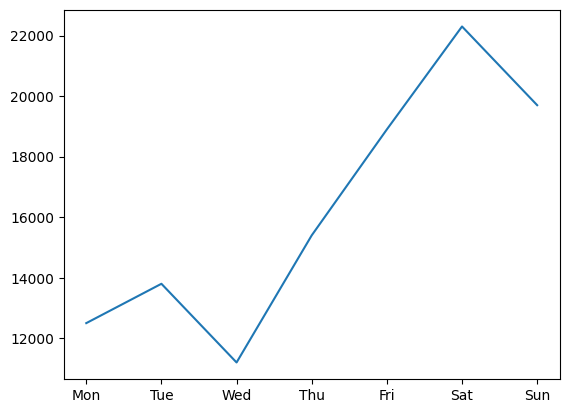

In [7]:
import matplotlib.pyplot as plt

week_sales.plot()
plt.show()

Ось і перший графік! `plt.show()` наприкінці каже «покажи графік». Без нього Colab теж намалює графік, але виведе над ним зайвий службовий рядок.

### Робимо графік зрозумілим
Графік без підписів — як таблиця без назв стовпців. Додамо три речі:

| Команда | Що додає |
|---|---|
| `plt.title("...")` | заголовок: **що** показує графік |
| `plt.xlabel("...")` | підпис горизонтальної осі (X) |
| `plt.ylabel("...")` | підпис вертикальної осі (Y), часто з **одиницями**: грн, шт., % |

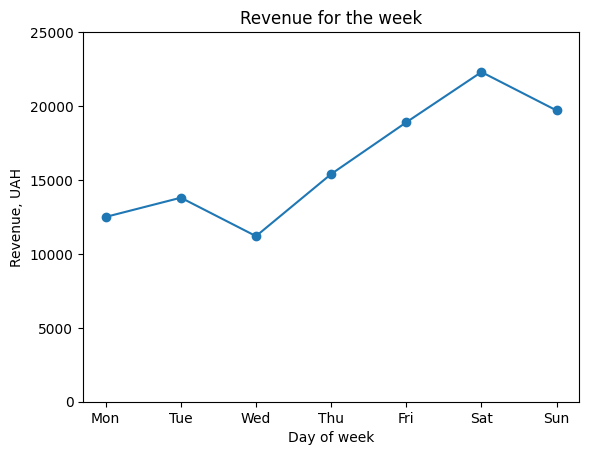

In [8]:
week_sales.plot(marker="o")          # marker="o" — точка на кожному значенні
plt.ylim(0, 25000)
plt.title("Revenue for the week")
plt.xlabel("Day of week")
plt.ylabel("Revenue, UAH")
plt.show()

💡 Усі команди `plt.` пишуться **в тій самій клітинці**, що й `.plot()`, і **перед** `plt.show()`.

### Інший тип графіка: `kind=`
За замовчуванням `.plot()` малює **лінію**. Параметр `kind` змінює тип графіка:

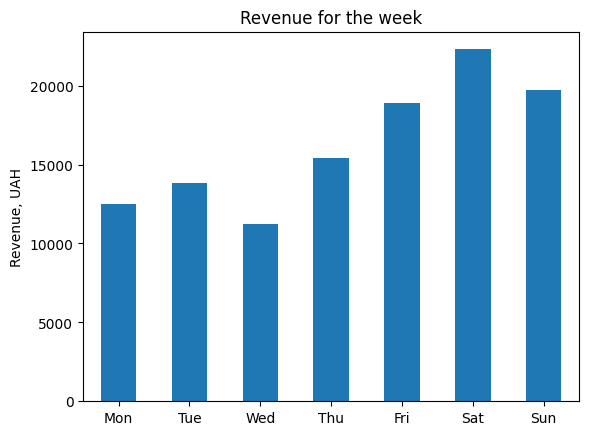

In [9]:
week_sales.plot(kind="bar", rot=0)   # rot=0 — підписи днів без нахилу
plt.title("Revenue for the week")
plt.xlabel("")
plt.ylabel("Revenue, UAH")
plt.show()

### Який графік обрати?

| Питання | Графік | `kind=` |
|---|---|---|
| Як змінювалося з часом? | лінійний | `"line"` (за замовчуванням) |
| Що більше, а що менше? | стовпчиковий | `"bar"` або `"barh"` (горизонтальний) |
| Як розподілені значення? | гістограма | `"hist"` |

Дні тижня йдуть по порядку в часі, тому підходить лінія: вона показує, як виручка росте до вихідних. Водночас кожен день — окрема категорія, тому підходять і стовпчики: вони дають порівняти дні між собою.

---
## Крок 3. DataFrame — ціла таблиця

**DataFrame** — це таблиця: кілька стовпців Series, поставлених поруч. Саме з DataFrame ви працюватимете 95% часу.

Найпростіше створити таблицю зі **словника**: ключ — назва стовпця, значення — список даних.

In [10]:
managers = pd.DataFrame({
    "manager": ["Olena", "Andrii", "Mariia", "Ihor"],
    "city":    ["Kyiv", "Lviv", "Kyiv", "Odesa"],
    "deals":   [34, 21, 45, 18],
    "revenue": [510000, 287000, 690000, 240000],
})

managers

,manager,city,deals,revenue
0,Olena,Kyiv,34,510000
1,Andrii,Lviv,21,287000
2,Mariia,Kyiv,45,690000
3,Ihor,Odesa,18,240000


Як читати таблицю:

| Що бачимо | Як називається |
|---|---|
| Назви вгорі: `manager`, `city`… | **стовпці** (columns) |
| Кожен горизонтальний ряд | **рядок** (row): тут один менеджер |
| Числа 0, 1, 2, 3 зліва | **індекс**: номер рядка (починається з 0) |

Кожен стовпець таблиці — це Series:

In [11]:
print(type(managers["revenue"]))

print("Total revenue:", managers["revenue"].sum())
print("Average number of deals:", managers["deals"].mean())

<class 'pandas.core.series.Series'>
Total revenue: 1727000
Average number of deals: 29.5


### 📈 Графік з таблиці
З таблиці обираємо, що буде підписами стовпчиків (`x`), а що їхньою висотою (`y`):

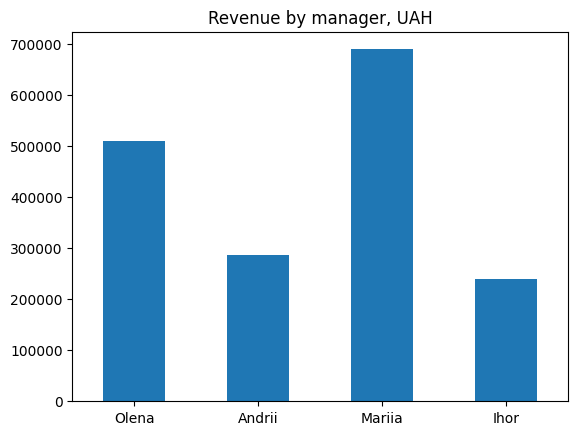

In [12]:
managers.plot(kind="bar", x="manager", y="revenue", rot=0, legend=False) #  rot - кут нахилу підписів на осі графіка
plt.title("Revenue by manager, UAH")
plt.xlabel("")
plt.show()

💡 `legend=False` прибирає легенду (віконце з назвою ряду даних). Коли на графіку один ряд, легенда не потрібна, бо все пояснює заголовок. `plt.xlabel("")` прибирає зайвий підпис `manager` під віссю.

---
## Крок 4. Завантажуємо дані з файлу

Вручну таблиці майже ніхто не створює: їх **читають з файлів**. Найпоширеніший формат — **CSV** (значення, розділені комами). Будь-яку таблицю Excel або Google Sheets можна зберегти як CSV.

Читаємо файл з продажами нашого магазину і кладемо його в змінну **`df`** (від *DataFrame*: аналітики найчастіше так називають головну таблицю).

In [13]:
df = pd.read_csv("sales.csv")

df

,order_id,order_date,delivery_date,customer_id,city,category,product,price,quantity,payment,channel,status,rating
0,100001,2025-01-01,NaN,C0230,Kyiv,Sports,Dumbbells 5 kg,950,4,Card,Website,Cancelled,NaN
1,100002,2025-01-01,2025-01-02,C0074,Odesa,Electronics,Smartwatch,4200,3,Google/Apple Pay,Website,Delivered,5.00
2,100003,2025-01-01,2025-01-05,C0216,Odesa,Electronics,Smartwatch,4200,1,Google/Apple Pay,Website,Delivered,NaN
3,100004,2025-01-01,2025-01-02,C0219,Kyiv,Electronics,Bluetooth speaker,2100,1,Cash on delivery,Instagram,Delivered,5.00
4,100005,2025-01-01,2025-01-06,C0026,Lviv,Home,Desk lamp,1100,1,Card,App,Delivered,4.00
...,...,...,...,...,...,...,...,...,...,...,...,...,...
2995,102996,2025-12-31,2026-01-01,C0114,Kyiv,Beauty,Face cream,520,1,Cash on delivery,Website,Delivered,4.00
2996,102997,2025-12-31,2026-01-01,C0008,Odesa,Sports,Dumbbells 5 kg,950,1,Card,Website,Delivered,NaN
2997,102998,2025-12-31,2026-01-01,C0219,Kyiv,Sports,Water bottle,350,1,Cash on delivery,App,Delivered,3.00
2998,102999,2025-12-31,2026-01-01,C0382,Kyiv,Sports,Yoga mat,700,1,Card,Website,Delivered,5.00


pandas показує лише початок і кінець великої таблиці, а внизу пише розмір: **3000 rows × 13 columns** (3000 рядків × 13 стовпців).

Ось що означає кожен стовпець:

| Стовпець | Що означає |
|---|---|
| `order_id` | номер замовлення |
| `order_date` | дата замовлення |
| `delivery_date` | дата доставки (порожньо, якщо замовлення скасували) |
| `customer_id` | код клієнта |
| `city` | місто клієнта |
| `category` | категорія товару |
| `product` | назва товару |
| `price` | ціна за одиницю, грн |
| `quantity` | кількість одиниць у замовленні |
| `payment` | спосіб оплати: `Card`, `Cash on delivery` (накладений платіж), `Google/Apple Pay` |
| `channel` | звідки прийшло замовлення: `Website`, `App`, `Instagram` |
| `status` | `Delivered` / `Cancelled` / `Returned` (доставлено / скасовано / повернено) |
| `rating` | оцінка клієнта від 1 до 5 (порожньо, якщо клієнт не оцінив) |


### Інші способи завантажити дані
| Звідки | Команда |
|---|---|
| Excel | `pd.read_excel("file.xlsx", sheet_name="Sheet1")` |
| CSV з крапкою з комою (часто буває в українському Excel) | `pd.read_csv("file.csv", sep=";")` |
| Google Таблиця з доступом за посиланням | `pd.read_csv("https://docs.google.com/spreadsheets/d/<ID>/export?format=csv")` |

**Як завантажити свій файл у Colab:** натисніть на іконку папки 📁 на панелі ліворуч → кнопка «Завантажити» → оберіть файл. Він з'явиться поруч з `sales.csv`, і його можна читати так само: `pd.read_csv("my_file.csv")`.

---
## Крок 5. Перший огляд даних

Будь-який аналіз починається з того, що ви **знайомитеся з таблицею**. Ось 5 команд, які аналітики запускають першими.

### 5.1 `head()` і `tail()`: перші й останні рядки

In [14]:
df.head()        # перші 5 рядків

,order_id,order_date,delivery_date,customer_id,city,category,product,price,quantity,payment,channel,status,rating
0,100001,2025-01-01,NaN,C0230,Kyiv,Sports,Dumbbells 5 kg,950,4,Card,Website,Cancelled,NaN
1,100002,2025-01-01,2025-01-02,C0074,Odesa,Electronics,Smartwatch,4200,3,Google/Apple Pay,Website,Delivered,5.00
2,100003,2025-01-01,2025-01-05,C0216,Odesa,Electronics,Smartwatch,4200,1,Google/Apple Pay,Website,Delivered,NaN
3,100004,2025-01-01,2025-01-02,C0219,Kyiv,Electronics,Bluetooth speaker,2100,1,Cash on delivery,Instagram,Delivered,5.00
4,100005,2025-01-01,2025-01-06,C0026,Lviv,Home,Desk lamp,1100,1,Card,App,Delivered,4.00


In [15]:
df.tail(3)       # останні 3 рядки (число в дужках — скільки рядків показати)

,order_id,order_date,delivery_date,customer_id,city,category,product,price,quantity,payment,channel,status,rating
2997,102998,2025-12-31,2026-01-01,C0219,Kyiv,Sports,Water bottle,350,1,Cash on delivery,App,Delivered,3.00
2998,102999,2025-12-31,2026-01-01,C0382,Kyiv,Sports,Yoga mat,700,1,Card,Website,Delivered,5.00
2999,103000,2025-12-31,2026-01-02,C0149,Odesa,Sports,Water bottle,350,4,Card,Website,Delivered,NaN


Є ще `df.sample(5)`: **5 випадкових рядків**. Це зручно, бо початок файлу не завжди схожий на решту даних.

### 5.2 `shape`: скільки рядків і стовпців

In [16]:
print(df.shape)
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

(3000, 13)
Rows: 3000
Columns: 13


💡 Зверніть увагу: `shape` пишемо **без дужок**, бо це властивість таблиці, а не дія. А `head()` — з дужками, бо це дія (метод).

### 5.3 `columns`: назви стовпців

In [17]:
df.columns

Index(['order_id', 'order_date', 'delivery_date', 'customer_id', 'city',
       'category', 'product', 'price', 'quantity', 'payment', 'channel',
       'status', 'rating'],
      dtype='object')

### 5.4 `info()`: типи даних і пропуски

Це **найважливіша** команда першого огляду. Вона показує для кожного стовпця:
- **Non-Null Count**: скільки клітинок заповнено (не порожні);
- **Dtype**: тип даних.

In [18]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   order_id       3000 non-null   int64  
 1   order_date     3000 non-null   object 
 2   delivery_date  2795 non-null   object 
 3   customer_id    3000 non-null   object 
 4   city           3000 non-null   object 
 5   category       3000 non-null   object 
 6   product        3000 non-null   object 
 7   price          3000 non-null   int64  
 8   quantity       3000 non-null   int64  
 9   payment        3000 non-null   object 
 10  channel        3000 non-null   object 
 11  status         3000 non-null   object 
 12  rating         1745 non-null   float64
dtypes: float64(1), int64(3), object(9)
memory usage: 304.8+ KB


**Як читати типи даних:**

| Тип | Що означає | Приклад у нас |
|---|---|---|
| `int64` | цілі числа | `order_id`, `price`, `quantity` |
| `float64` | дробові числа | `rating` |
| `object` або `str` | текст (назва залежить від версії pandas) | `city`, `product`, `status` |

**Що ми помітили:**
1. У `delivery_date` і `rating` менше 3000 заповнених значень: це **пропуски**. Скасовані замовлення не доставляли, а не всі клієнти ставлять оцінки. Це нормально.
2. `rating` має тип `float64`, хоча оцінки цілі. Справа в тому, що в стовпці з цілими числами (`int64`) не може бути порожніх клітинок, тому pandas зберігає такий стовпець як дробовий. (Текстовий стовпець, як-от `delivery_date`, пропуски містити може.) Тому й оцінки показані як `5.00`.
3. Дати (`order_date`) зчиталися як **текст**. Поки що нам це не заважає, а в блокноті 6 ми перетворимо їх на справжні дати.

### 5.5 `describe()`: швидка статистика по числах

In [19]:
df.describe()

,order_id,price,quantity,rating
count,3 000.00,3 000.00,3 000.00,1 745.00
mean,101 500.50,957.10,1.39,3.90
std,866.17,854.54,0.74,1.17
min,100 001.00,180.00,1.00,1.00
25%,100 750.75,350.00,1.00,3.00
50%,101 500.50,700.00,1.00,4.00
75%,102 250.25,1 200.00,2.00,5.00
max,103 000.00,4 200.00,4.00,5.00


**Як читати `describe()`:**

| Рядок | Що означає |
|---|---|
| `count` | скільки заповнених значень |
| `mean` | середнє |
| `std` | стандартне відхилення: наскільки сильно значення «розкидані» |
| `min` / `max` | найменше / найбільше |
| `25%` | чверть значень менші за це число |
| `50%` | **медіана**: рівно половина значень менша, половина більша |
| `75%` | три чверті значень менші за це число |

**Що видно одразу:** ціни від 180 до 4200 грн, але медіана лише 700 грн, тобто дешевих товарів купують більше. Кількість у замовленні зазвичай 1 (медіана = 1), максимум 4. Середня оцінка близько 4.

⚠️ Для `order_id` статистика не має сенсу: середній номер замовлення нікому не потрібен. `describe()` просто рахує все, що схоже на числа.

---
## 📈 Гістограма: як розподілені значення

`describe()` дав нам числа, а **гістограма** показує картину. Вона ділить ціни на інтервали («кошики») і рахує, скільки замовлень потрапило в кожен. Чим вищий стовпчик, тим більше замовлень у цьому ціновому діапазоні.

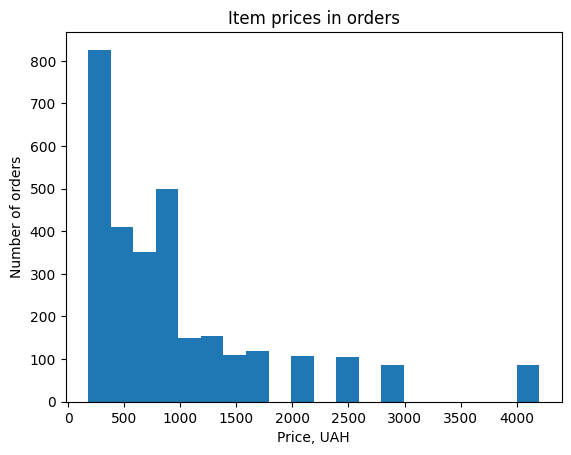

In [20]:
df["price"].plot(kind="hist", bins=20)     # bins — на скільки інтервалів поділити
plt.title("Item prices in orders")
plt.xlabel("Price, UAH")
plt.ylabel("Number of orders")
plt.show()

**Що видно:** більшість замовлень — товари до 1000 грн, а дорогі (понад 2000 грн) купують рідко. Саме тому медіана (700 грн) помітно менша за середнє (957 грн): кілька дорогих покупок «тягнуть» середнє вгору.

Спробуйте змінити `bins=20` на `bins=5` або `bins=50` і подивіться, як змінюється картина.

---
## Крок 6. Що всередині текстових стовпців

Для тексту середнього не порахуєш. Зате можна дізнатися, **які значення є** і **скільки разів трапляється кожне**.

In [ ]:
print("Cities:", df["city"].unique())          # unique — список різних значень
print("Number of cities:", df["city"].nunique())

Cities: ['Kyiv' 'Odesa' 'Lviv' 'Dnipro' 'Kharkiv']
Number of cities: 5


In [21]:
df["city"].value_counts()                      # скільки замовлень з кожного міста

,count
city,
Kyiv,957
Lviv,678
Kharkiv,493
Dnipro,442
Odesa,430


`value_counts()` — одна з найкорисніших команд аналітика. Вона одразу сортує результат від найчастішого до найрідшого. Детальніше про підрахунки поговоримо в блокноті 4.

### 📈 Підрахунок → графік
Результат `value_counts()` — це Series, тож його одразу можна намалювати:

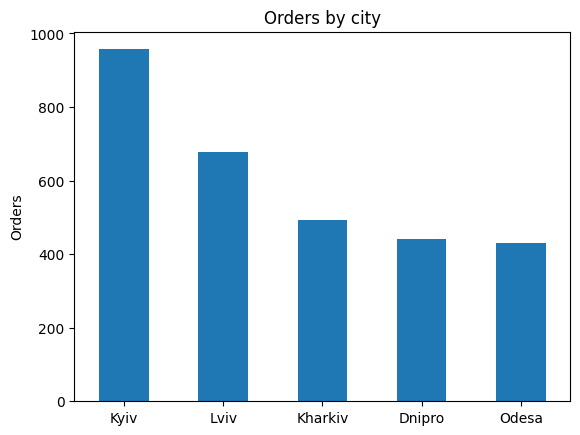

In [22]:
df["city"].value_counts().plot(kind="bar", rot=0)
plt.title("Orders by city")
plt.xlabel("")
plt.ylabel("Orders")
plt.show()

💡 `value_counts()` уже відсортував міста від більшого до меншого, тому стовпчики йдуть «сходинками». Відсортований графік читати значно легше.

---
## Крок 7. Перші розрахунки

Щоб порахувати щось по стовпцю, оберіть його в квадратних дужках і допишіть назву дії:

| Дія | Що рахує |
|---|---|
| `.sum()` | суму |
| `.mean()` | середнє |
| `.median()` | медіану |
| `.min()` / `.max()` | мінімум / максимум |
| `.count()` | кількість заповнених значень |

In [23]:
print("Units sold:", df["quantity"].sum())
print("Average item price:", df["price"].mean().round(2))
print("Median price:", df["price"].median())
print("Average rating:", df["rating"].mean().round(2))
print("Orders with a rating:", df["rating"].count())

Units sold: 4182
Average item price: 957.1
Median price: 700.0
Average rating: 3.9
Orders with a rating: 1745


💡 Порожні клітинки (`NaN`) pandas **автоматично пропускає**: середня оцінка рахується тільки по замовленнях, де оцінку поставили.

Мінімум і максимум працюють навіть для дат, записаних як текст, бо формат `рік-місяць-день` сортується правильно:

In [24]:
print("First order:", df["order_date"].min())
print("Last order:", df["order_date"].max())

First order: 2025-01-01
Last order: 2025-12-31


---
## Крок 8. Зберігаємо результат у файл

Таблицю можна зберегти назад у файл. **`index=False`** означає «не записувати номери рядків окремим стовпцем», і майже завжди вам потрібен саме цей варіант.

In [25]:
first_100 = df.head(100)

first_100.to_csv("first_100_orders.csv", index=False)      # у CSV
first_100.to_excel("first_100_orders.xlsx", index=False)   # в Excel

print("Files saved!")

Files saved!


Щоб завантажити файл на комп'ютер, відкрийте панель 📁 ліворуч, натисніть ⋮ біля файлу → «Завантажити».

---
# ✍️ Практика

У файлі **`customers.csv`** зберігається список клієнтів магазину. Попрацюйте з ним самостійно.

⚠️ Головну таблицю `df` не перезаписуйте: клієнтів кладіть у нову змінну `customers`.

**Завдання 1.** Прочитайте файл `customers.csv` у змінну `customers` і покажіть перші 5 рядків.

In [27]:

customers = pd.read_csv("customers.csv")

customers.head()


,customer_id,name,city,age,registration_date
0,C0001,Sofiia,Lviv,29,2023-05-05
1,C0002,Tetiana,Dnipro,27,2024-12-24
2,C0003,Andrii,Kharkiv,35,2024-12-22
3,C0004,Iryna,Dnipro,29,2023-02-23
4,C0005,Sofiia,Odesa,40,2024-11-10


**Завдання 2.** Скільки в таблиці клієнтів (рядків) і скільки стовпців?

In [ ]:

print("Кількість клієнтів:", customers.shape[0])
print("Кількість стовпців:", customers.shape[1])


Кількість клієнтів: 400
Кількість стовпців: 5


**Завдання 3.** Подивіться типи даних. Чи є в таблиці пропуски?

In [ ]:
print(customers.info())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   customer_id        400 non-null    object
 1   name               400 non-null    object
 2   city               400 non-null    object
 3   age                400 non-null    int64 
 4   registration_date  400 non-null    object
dtypes: int64(1), object(4)
memory usage: 15.8+ KB
None


**Завдання 4.** Який середній, наймолодший і найстарший вік клієнтів?

*Підказка: можна порахувати кожне окремо або подивитися все одразу в `describe()`.*

In [ ]:
# print("Середній вік:", customers["age"].mean().round(1))
# print("Наймолодший:", customers["age"].min())
# print("Найстарший:", customers["age"].max())
print(customers["age"].describe())



count   400.00
mean     32.51
std       8.48
min      18.00
25%      27.00
50%      32.00
75%      39.00
max      63.00
Name: age, dtype: float64


**Завдання 5.** Скільки клієнтів живе в кожному місті?

In [28]:
customers["city"].value_counts()


,count
city,
Kyiv,131
Lviv,89
Kharkiv,66
Odesa,58
Dnipro,56


**Завдання 6 ⭐.** Прочитайте файл `products.csv` у змінну `products`. Скільки товарів у кожній категорії? Яка найвища ціна товару і яка середня собівартість (`cost`)?

In [30]:
products = pd.read_csv("products.csv")
display(products.head())
print("Кількість товарів у кожній категорії:")
print(products["category"].value_counts())
print("\nНайвища ціна:", products["price"].max())
print("Середня вартість:", products["cost"].mean().round(2))

,product_id,product,category,price,cost
0,P01,Headphones,Electronics,1500,900
1,P02,Power bank,Electronics,900,520
2,P03,Smartwatch,Electronics,4200,2900
3,P04,Bluetooth speaker,Electronics,2100,1300
4,P05,T-shirt,Clothing,450,180


Кількість товарів у кожній категорії:
category
Electronics    4
Clothing       4
Home           4
Beauty         3
Sports         3
Name: count, dtype: int64

Найвища ціна: 4200
Середня вартість: 707.78


**Завдання 7 📈.** Побудуйте стовпчиковий графік: скільки клієнтів (таблиця `customers`) живе в кожному місті. Додайте заголовок і підпис осі Y.

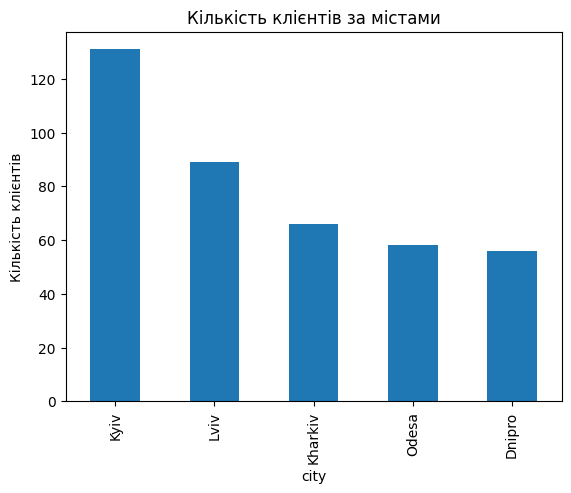

In [31]:
customers["city"].value_counts()
customers["city"].value_counts().plot(kind="bar")
import matplotlib.pyplot as plt

customers["city"].value_counts().plot(kind="bar")

plt.title("Кількість клієнтів за містами")
plt.ylabel("Кількість клієнтів")

plt.show()


**Завдання 8 📈⭐.** Побудуйте гістограму віку клієнтів з 15 інтервалами (`bins=15`), із заголовком і підписами обох осей. Клієнти якого віку трапляються найчастіше?

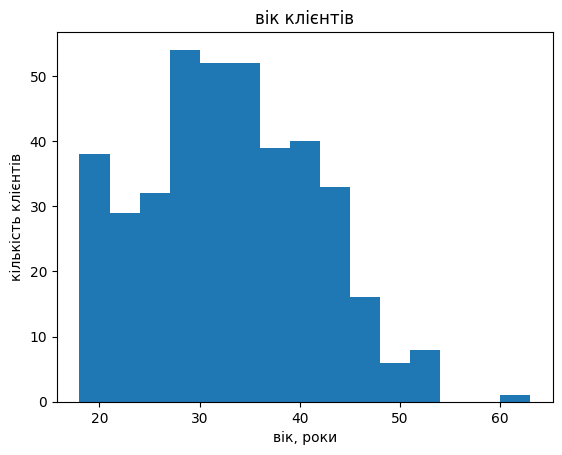

In [35]:
import matplotlib.pyplot as plt
customers["age"].plot(kind="hist", bins=15)
plt.title("вік клієнтів")
plt.xlabel("вік, роки")
plt.ylabel("кількість клієнтів")
plt.show()

---
# 📋 Шпаргалка блокнота 1

| Код | Що робить |
|---|---|
| `import pandas as pd` | підключити pandas |
| `pd.Series([...], index=[...])` | створити стовпець з підписами |
| `pd.DataFrame({"col": [...]})` | створити таблицю |
| `pd.read_csv("file.csv")` / `pd.read_excel("file.xlsx")` | прочитати файл |
| `df.head()`, `df.tail()`, `df.sample(5)` | перші, останні, випадкові рядки |
| `df.shape` | (рядки, стовпці) |
| `df.columns` | назви стовпців |
| `df.info()` | типи даних і пропуски |
| `df.describe()` | статистика по числових стовпцях |
| `df["col"].unique()`, `.nunique()` | різні значення / їх кількість |
| `df["col"].value_counts()` | скільки разів трапляється кожне значення |
| `df["col"].sum()`, `.mean()`, `.median()`, `.min()`, `.max()`, `.count()` | підсумки |
| `df.to_csv("file.csv", index=False)` / `df.to_excel(...)` | зберегти у файл |

**📈 Графіки**

| Код | Що робить |
|---|---|
| `import matplotlib.pyplot as plt` | підключити matplotlib |
| `series.plot()` | лінійний графік |
| `series.plot(kind="bar", rot=0)` | стовпчиковий графік (підписи без нахилу) |
| `df.plot(kind="bar", x="col1", y="col2")` | графік з таблиці: що підписи, що висота |
| `series.plot(kind="hist", bins=20)` | гістограма |
| `marker="o"`, `legend=False` | точки на лінії / без легенди |
| `plt.title()`, `plt.xlabel()`, `plt.ylabel()` | заголовок і підписи осей |
| `plt.show()` | показати графік |

---
### ➡️ Далі: блокнот 2 «Вибір, фільтрація та сортування»
Навчимося відбирати потрібні стовпці й рядки: «покажи всі замовлення зі Львова дорожчі за 1000 грн». А 📈 у графіках навчимося налаштовувати вигляд: розмір, колір, підписи значень, виділення головного.

In [ ]:
# @title 💡 Розв'язки практики: відкривайте, лише якщо справді застрягли
# Спершу спробуйте розв'язати кожне завдання самостійно в клітинках «Ваш код тут».

# ---------- Завдання 1 ----------
customers = pd.read_csv("customers.csv")
display(customers.head())

# ---------- Завдання 2 ----------
print("Customers:", customers.shape[0])
print("Columns:", customers.shape[1])

# ---------- Завдання 3 ----------
customers.info()
# У кожному стовпці 400 заповнених значень (Non-Null Count), тобто пропусків немає.

# ---------- Завдання 4 ----------
print("Average age:", customers["age"].mean().round(1))
print("Youngest:", customers["age"].min())
print("Oldest:", customers["age"].max())

# ---------- Завдання 5 ----------
display(customers["city"].value_counts())

# ---------- Завдання 6 ⭐ ----------
products = pd.read_csv("products.csv")

print(products["category"].value_counts())
print("\nHighest price:", products["price"].max())
print("Average cost:", products["cost"].mean().round(2))

# ---------- Завдання 7 📈 ----------
customers["city"].value_counts().plot(kind="bar", rot=0)
plt.title("Customers by city")
plt.xlabel("")
plt.ylabel("Customers")
plt.show()

# ---------- Завдання 8 📈⭐ ----------
customers["age"].plot(kind="hist", bins=15)
plt.title("Customer age")
plt.xlabel("Age, years")
plt.ylabel("Number of customers")
plt.show()
# Найбільше клієнтів віком приблизно 25–40 років, а людей за 50 зовсім мало.
